# 02 — Multi-City Exploratory Data Analysis

## Restaurant Customer Intelligence

This notebook compares customer behavior across the ten U.S. cities included in
the dataset.

### Business questions

1. How is the customer base distributed across cities?
2. Which cities show the highest customer spending?
3. Which markets show the highest visit frequency and customer income?
4. Where is Premium membership most prevalent?
5. How do food preferences differ across markets?
6. Which cities represent the most attractive opportunities for deeper restaurant
   intelligence and recommendation analysis?

The objective is not to create a single arbitrary city ranking, but to compare
markets across customer volume, economic value, engagement, and food preferences.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
DATA_PATH = Path("../data/processed/customers_clean.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 30,000
Columns: 13


In [3]:
df.head()

,id_persona,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,31.00,Masculino,Miami,Alto,6.00,67.51,Sí,No,Vegetariano,Sí,Efectivo,6425
1,9446112038,40.00,Femenino,Denver,Medio,2.00,44.92,Sí,Sí,Mariscos,No,Efectivo,2374
2,3098363243,62.00,Femenino,Denver,Bajo,2.00,9.24,Sí,Sí,Vegetariano,No,Efectivo,1110
3,4013002847,41.00,Masculino,Boston,Alto,5.00,30.74,Sí,Sí,Carnes,Sí,Tarjeta,6931
4,7372911048,49.00,Femenino,San Diego,Bajo,0.00,0.00,No,No,Carnes,No,Tarjeta,1350


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   edad                       29692 non-null  float64
 2   genero                     30000 non-null  str    
 3   ciudad_residencia          30000 non-null  str    
 4   estrato_socioeconomico     30000 non-null  str    
 5   frecuencia_visita          28453 non-null  float64
 6   promedio_gasto_comida      29855 non-null  float64
 7   ocio                       30000 non-null  str    
 8   consume_licor              30000 non-null  str    
 9   preferencias_alimenticias  28597 non-null  str    
 10  membresia_premium          30000 non-null  str    
 11  tipo_de_pago_mas_usado     30000 non-null  str    
 12  ingresos_mensuales         30000 non-null  int64  
dtypes: float64(3), int64(2), str(8)
memory usage: 4.1 MB


## 1. Market overview

Cities are compared across four complementary dimensions:

- **Customer volume:** number of customers in each city.
- **Customer value:** average and median food spending.
- **Engagement:** visit frequency and Premium membership.
- **Purchasing power:** customer income and socioeconomic profile.

Food preferences are analyzed separately to understand differences in restaurant
demand across markets.

Missing values are excluded only from calculations involving the affected
variable. Customer records are not removed globally.

In [5]:
city_customers = (
    df["ciudad_residencia"]
    .value_counts()
    .rename_axis("city")
    .reset_index(name="customers")
)

city_customers["share_pct"] = (
    city_customers["customers"] / len(df) * 100
).round(2)

city_customers

,city,customers,share_pct
0,Chicago,5384,17.95
1,NYC,4769,15.90
2,Miami,3186,10.62
3,San Diego,3075,10.25
4,Dallas,2602,8.67
5,Boston,2547,8.49
6,Denver,2523,8.41
7,Houston,2212,7.37
8,Seattle,2191,7.30
9,Phoenix,1511,5.04


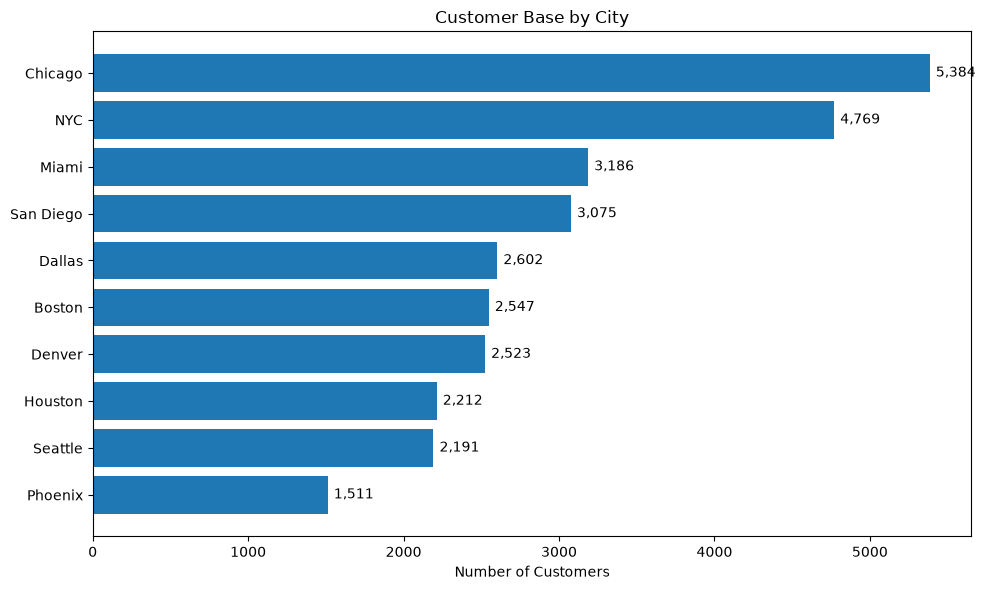

In [6]:
city_plot = city_customers.sort_values("customers")

plt.figure(figsize=(10, 6))

plt.barh(
    city_plot["city"],
    city_plot["customers"]
)

plt.title("Customer Base by City")
plt.xlabel("Number of Customers")
plt.ylabel("")

for i, value in enumerate(city_plot["customers"]):
    plt.text(
        value + 40,
        i,
        f"{value:,}",
        va="center"
    )

plt.tight_layout()
plt.show()

### Finding: customer volume

Customer volume varies considerably across markets.

Chicago has the largest customer base with 5,384 customers, followed by NYC
with 4,769. Miami ranks third with 3,186 customers.

Customer volume alone does not indicate market value. The following analyses
compare spending, engagement, purchasing power, and Premium membership to
determine whether cities with smaller customer bases may represent higher-value
markets.

## 2. Customer spending by city

Average and median food spending are compared across cities.

Using both measures helps distinguish overall spending intensity from the
behavior of the typical customer and reduces the risk of interpreting a city
based only on high-spending observations.

In [7]:
city_spending = (
    df.groupby("ciudad_residencia")
      .agg(
          customers=("id_persona", "count"),
          avg_spending=("promedio_gasto_comida", "mean"),
          median_spending=("promedio_gasto_comida", "median")
      )
      .round(2)
      .sort_values("avg_spending", ascending=False)
)

city_spending

,customers,avg_spending,median_spending
ciudad_residencia,,,
Miami,3186,39.82,31.60
NYC,4769,37.12,29.60
Seattle,2191,36.86,32.43
Phoenix,1511,36.54,29.36
San Diego,3075,34.75,28.27
Denver,2523,34.26,27.83
Boston,2547,29.49,22.79
Dallas,2602,28.70,21.60
Houston,2212,26.02,22.20


In [8]:
high_spending_threshold = df["promedio_gasto_comida"].quantile(0.75)

print(f"75th percentile spending threshold: ${high_spending_threshold:.2f}")

75th percentile spending threshold: $44.40


In [9]:
high_spending_by_city = (
    df.assign(
        high_spender=df["promedio_gasto_comida"] >= high_spending_threshold
    )
    .groupby("ciudad_residencia")["high_spender"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
    .rename("high_spenders_pct")
)

high_spending_by_city

ciudad_residencia
Seattle     33.82
Miami       32.80
NYC         30.11
San Diego   28.81
Phoenix     27.27
Denver      25.68
Boston      22.85
Chicago     18.57
Dallas      17.29
Houston     11.98
Name: high_spenders_pct, dtype: float64

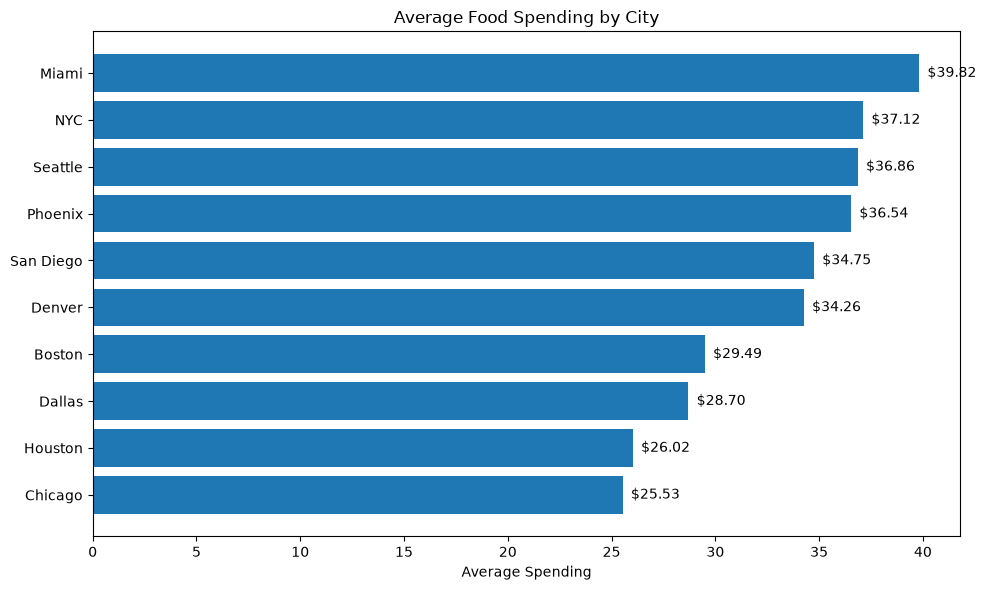

In [10]:
spending_plot = (
    city_spending
    .sort_values("avg_spending", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    spending_plot.index,
    spending_plot["avg_spending"]
)

plt.title("Average Food Spending by City")
plt.xlabel("Average Spending")
plt.ylabel("")

for i, value in enumerate(spending_plot["avg_spending"]):
    plt.text(
        value + 0.4,
        i,
        f"${value:.2f}",
        va="center"
    )

plt.tight_layout()
plt.show()

### Finding: customer spending

Customer volume and customer value show different market patterns.

Miami has the highest average food spending at $39.82, followed by NYC ($37.12)
and Seattle ($36.86). Miami also shows a high median spending level ($31.60),
indicating that its result is not driven only by a small number of high-spending
customers.

Seattle has the highest median spending ($32.43) and the largest proportion of
customers above the overall 75th-percentile spending threshold (33.82%), closely
followed by Miami (32.80%).

Chicago presents the opposite pattern: despite having the largest customer base,
it has the lowest average spending ($25.53).

**Business insight:** customer volume alone is not an adequate measure of market
value. Miami and Seattle show particularly strong spending profiles, while NYC
combines a large customer base with relatively high spending.

In [11]:
city_engagement = (
    df.groupby("ciudad_residencia")
      .agg(
          avg_frequency=("frecuencia_visita", "mean"),
          median_frequency=("frecuencia_visita", "median"),
          premium_pct=(
              "membresia_premium",
              lambda x: (x == "Sí").mean() * 100
          )
      )
      .round(2)
      .sort_values("avg_frequency", ascending=False)
)

city_engagement

,avg_frequency,median_frequency,premium_pct
ciudad_residencia,,,
Miami,4.78,5.00,53.17
San Diego,4.67,5.00,48.85
Seattle,4.42,4.00,46.69
Boston,4.33,4.00,44.72
Denver,4.23,4.00,42.33
Chicago,4.21,4.00,41.14
Phoenix,4.18,4.00,41.63
Dallas,4.01,4.00,38.12
NYC,3.99,4.00,37.22


In [12]:
city_purchasing_power = (
    df.groupby("ciudad_residencia")
      .agg(
          avg_income=("ingresos_mensuales", "mean"),
          median_income=("ingresos_mensuales", "median"),
          very_high_pct=(
              "estrato_socioeconomico",
              lambda x: (x == "Muy Alto").mean() * 100
          )
      )
      .round(2)
      .sort_values("avg_income", ascending=False)
)

city_purchasing_power

,avg_income,median_income,very_high_pct
ciudad_residencia,,,
Miami,"6,476.26","5,206.00",25.08
San Diego,"6,087.04","4,760.00",22.70
Seattle,"5,719.33","4,026.00",20.36
Boston,"5,658.08","3,657.00",20.93
Denver,"5,324.44","3,480.00",16.09
Phoenix,"5,245.45","3,253.00",16.81
Chicago,"5,202.31","3,244.50",17.22
Dallas,"4,861.31","3,055.00",14.49
NYC,"4,782.80","3,001.00",14.80


In [13]:
city_comparison = (
    city_spending
    .join(city_engagement)
    .join(city_purchasing_power)
)

city_comparison = city_comparison.join(high_spending_by_city)

city_comparison.round(2)

,customers,avg_spending,median_spending,avg_frequency,median_frequency,premium_pct,avg_income,median_income,very_high_pct,high_spenders_pct
ciudad_residencia,,,,,,,,,,
Miami,3186,39.82,31.60,4.78,5.00,53.17,"6,476.26","5,206.00",25.08,32.80
NYC,4769,37.12,29.60,3.99,4.00,37.22,"4,782.80","3,001.00",14.80,30.11
Seattle,2191,36.86,32.43,4.42,4.00,46.69,"5,719.33","4,026.00",20.36,33.82
Phoenix,1511,36.54,29.36,4.18,4.00,41.63,"5,245.45","3,253.00",16.81,27.27
San Diego,3075,34.75,28.27,4.67,5.00,48.85,"6,087.04","4,760.00",22.70,28.81
Denver,2523,34.26,27.83,4.23,4.00,42.33,"5,324.44","3,480.00",16.09,25.68
Boston,2547,29.49,22.79,4.33,4.00,44.72,"5,658.08","3,657.00",20.93,22.85
Dallas,2602,28.70,21.60,4.01,4.00,38.12,"4,861.31","3,055.00",14.49,17.29
Houston,2212,26.02,22.20,3.95,4.00,36.53,"4,779.63","3,017.50",14.92,11.98


In [14]:
market_summary = city_comparison[
    [
        "customers",
        "avg_spending",
        "avg_frequency",
        "premium_pct",
        "avg_income",
        "very_high_pct",
        "high_spenders_pct"
    ]
].copy()

market_summary.sort_values(
    "avg_spending",
    ascending=False
).round(2)

,customers,avg_spending,avg_frequency,premium_pct,avg_income,very_high_pct,high_spenders_pct
ciudad_residencia,,,,,,,
Miami,3186,39.82,4.78,53.17,"6,476.26",25.08,32.80
NYC,4769,37.12,3.99,37.22,"4,782.80",14.80,30.11
Seattle,2191,36.86,4.42,46.69,"5,719.33",20.36,33.82
Phoenix,1511,36.54,4.18,41.63,"5,245.45",16.81,27.27
San Diego,3075,34.75,4.67,48.85,"6,087.04",22.70,28.81
Denver,2523,34.26,4.23,42.33,"5,324.44",16.09,25.68
Boston,2547,29.49,4.33,44.72,"5,658.08",20.93,22.85
Dallas,2602,28.70,4.01,38.12,"4,861.31",14.49,17.29
Houston,2212,26.02,3.95,36.53,"4,779.63",14.92,11.98


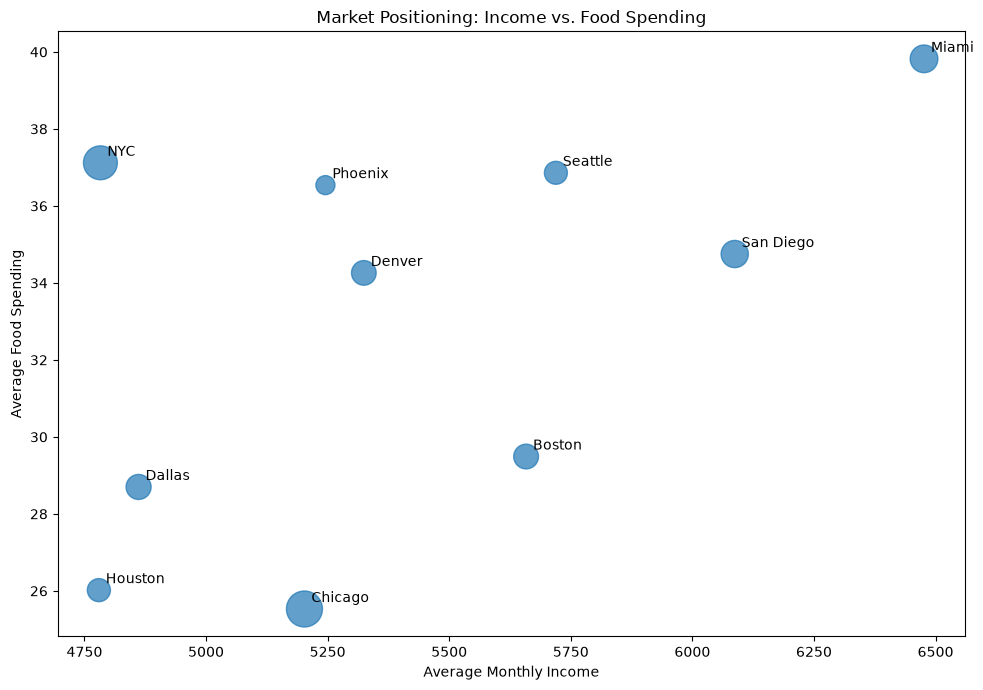

In [15]:
plt.figure(figsize=(10, 7))

plt.scatter(
    market_summary["avg_income"],
    market_summary["avg_spending"],
    s=market_summary["customers"] / 8,
    alpha=0.7
)

for city, row in market_summary.iterrows():
    plt.annotate(
        city,
        (row["avg_income"], row["avg_spending"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Market Positioning: Income vs. Food Spending")
plt.xlabel("Average Monthly Income")
plt.ylabel("Average Food Spending")

plt.tight_layout()
plt.show()

### Finding: market positioning

The relationship between purchasing power and restaurant spending reveals
distinct market profiles.

Miami occupies the strongest high-income / high-spending position, combining
the highest average monthly income with the highest average food spending.
Its customer base is also substantial, making it an attractive market from both
value and scale perspectives.

NYC shows a different but notable pattern: despite a lower average income, its
customers maintain one of the highest average food-spending levels and represent
the second-largest customer base. This may indicate comparatively strong
restaurant spending intensity.

Seattle also combines relatively high purchasing power with high food spending,
while Chicago demonstrates that customer volume does not necessarily translate
into higher customer value: it has the largest customer base but one of the
lowest average spending levels.

**Business insight:** markets should not be evaluated through a single metric.
Miami stands out for purchasing power and spending, NYC for scale combined with
high spending intensity, and Seattle for a strong high-value customer profile.

In [16]:
food_preferences = (
    df["preferencias_alimenticias"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

food_preferences

preferencias_alimenticias
Carnes        27.68
Vegetariano   23.01
Mariscos      18.23
Vegano        11.42
Pescado       10.43
Otro           9.23
Name: proportion, dtype: float64

In [17]:
preferences_by_city = pd.crosstab(
    df["ciudad_residencia"],
    df["preferencias_alimenticias"],
    normalize="index"
).mul(100).round(2)

preferences_by_city

preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
ciudad_residencia,,,,,,
Boston,21.88,20.16,8.10,11.12,9.78,28.96
Chicago,31.06,13.60,11.55,10.67,11.16,21.95
Dallas,33.24,14.80,10.07,9.66,10.43,21.80
Denver,26.28,19.46,7.15,10.35,10.73,26.03
Houston,33.71,15.68,11.21,10.78,9.27,19.35
Miami,16.81,26.94,9.64,10.10,12.57,23.95
NYC,33.11,17.49,8.67,9.54,12.87,18.32
Phoenix,28.99,14.56,10.73,13.94,10.80,20.98
San Diego,22.74,20.24,6.72,9.98,14.11,26.20


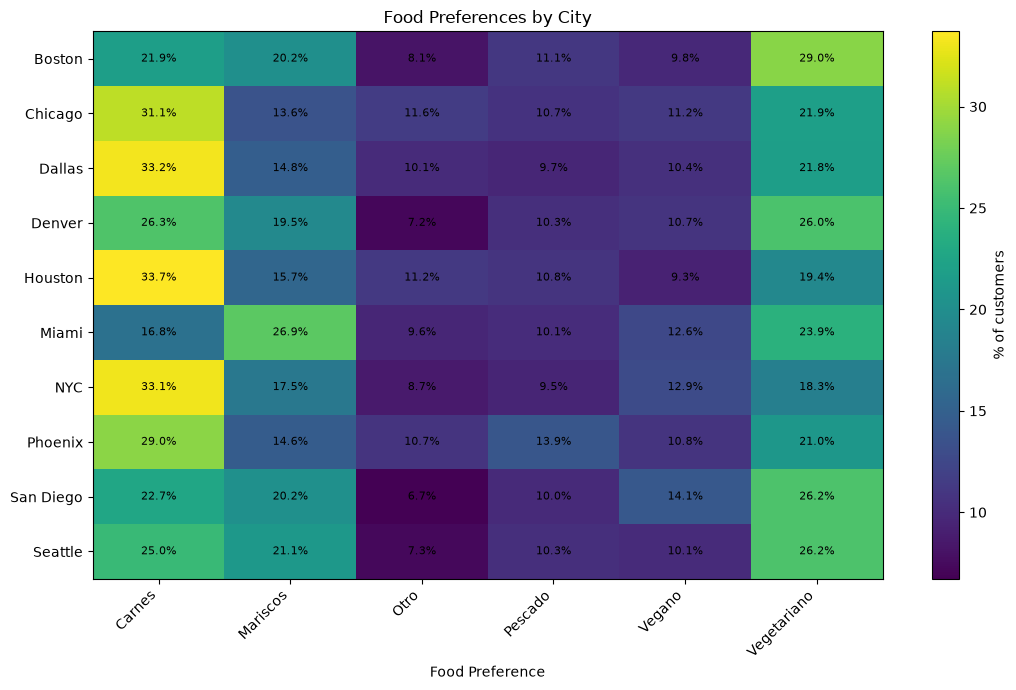

In [18]:
plt.figure(figsize=(11, 7))

plt.imshow(
    preferences_by_city,
    aspect="auto"
)

plt.colorbar(label="% of customers")

plt.xticks(
    range(len(preferences_by_city.columns)),
    preferences_by_city.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(preferences_by_city.index)),
    preferences_by_city.index
)

plt.title("Food Preferences by City")
plt.xlabel("Food Preference")
plt.ylabel("")

for i in range(len(preferences_by_city.index)):
    for j in range(len(preferences_by_city.columns)):
        plt.text(
            j,
            i,
            f"{preferences_by_city.iloc[i, j]:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

### Finding: food preferences differ substantially across markets

Food preferences show meaningful differences across cities, suggesting that
restaurant demand cannot be treated as homogeneous across markets.

Miami presents one of the most distinctive profiles: only 16.81% of customers
report a preference for meat, the lowest proportion among the ten cities, while
26.94% prefer seafood, the highest proportion in the dataset.

Other markets also show distinctive patterns:

- Boston has the highest vegetarian preference (28.96%).
- San Diego has the highest vegan preference (14.11%).
- Phoenix has the highest fish preference (13.94%).
- Houston, Dallas, and NYC show particularly strong meat-oriented profiles.

**Business insight:** restaurant recommendations and marketing strategies should
account for local preference profiles rather than applying the same category mix
across all cities.

In [19]:
overall_preferences = (
    df["preferencias_alimenticias"]
    .value_counts(normalize=True)
    .mul(100)
)

overall_preferences

preferencias_alimenticias
Carnes        27.68
Vegetariano   23.01
Mariscos      18.23
Vegano        11.42
Pescado       10.43
Otro           9.23
Name: proportion, dtype: float64

In [20]:
preference_affinity = (
    preferences_by_city
    .div(overall_preferences, axis=1)
    .mul(100)
    .round(1)
)

preference_affinity

preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
ciudad_residencia,,,,,,
Boston,79.00,110.60,87.80,106.60,85.60,125.90
Chicago,112.20,74.60,125.20,102.30,97.70,95.40
Dallas,120.10,81.20,109.10,92.60,91.30,94.70
Denver,94.90,106.80,77.50,99.20,93.90,113.10
Houston,121.80,86.00,121.50,103.30,81.10,84.10
Miami,60.70,147.80,104.50,96.80,110.00,104.10
NYC,119.60,96.00,94.00,91.50,112.70,79.60
Phoenix,104.70,79.90,116.30,133.60,94.50,91.20
San Diego,82.10,111.10,72.80,95.70,123.50,113.90


In [21]:
city_signature = pd.DataFrame({
    "strongest_preference": preference_affinity.idxmax(axis=1),
    "affinity_index": preference_affinity.max(axis=1)
}).sort_values("affinity_index", ascending=False)

city_signature

,strongest_preference,affinity_index
ciudad_residencia,,
Miami,Mariscos,147.80
Phoenix,Pescado,133.60
Boston,Vegetariano,125.90
Chicago,Otro,125.20
San Diego,Vegano,123.50
Houston,Carnes,121.80
Dallas,Carnes,120.10
NYC,Carnes,119.60
Seattle,Mariscos,116.00


### Finding: each market has a distinctive food-preference profile

Preference affinity highlights which food categories are disproportionately
represented in each city compared with the overall ten-city customer base.

Miami shows the strongest market-specific signal in the dataset. Seafood
preference has an affinity index of 147.8, meaning it is approximately 47.8%
more represented in Miami than in the overall customer population.

Other notable market signatures include:

- Phoenix: Fish — affinity index 133.6
- Boston: Vegetarian — 125.9
- San Diego: Vegan — 123.5
- Houston: Meat — 121.8
- Dallas: Meat — 120.1
- NYC: Meat — 119.6
- Seattle: Seafood — 116.0
- Denver: Vegetarian — 113.1

**Business insight:** market-level affinity provides a more actionable signal
than absolute preference percentages alone. It can support localized restaurant
positioning, customer targeting, and recommendation strategies.

## 5. Strategic market comparison

Markets are ranked independently across several business dimensions rather than
combined into an arbitrary single score.

Lower rank values indicate stronger relative performance.

In [22]:
strategic_markets = market_summary.copy()

strategic_markets["spending_rank"] = (
    strategic_markets["avg_spending"]
    .rank(ascending=False, method="min")
    .astype(int)
)

strategic_markets["income_rank"] = (
    strategic_markets["avg_income"]
    .rank(ascending=False, method="min")
    .astype(int)
)

strategic_markets["premium_rank"] = (
    strategic_markets["premium_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

strategic_markets["volume_rank"] = (
    strategic_markets["customers"]
    .rank(ascending=False, method="min")
    .astype(int)
)

strategic_markets["high_spender_rank"] = (
    strategic_markets["high_spenders_pct"]
    .rank(ascending=False, method="min")
    .astype(int)
)

strategic_markets[
    [
        "avg_spending",
        "spending_rank",
        "avg_income",
        "income_rank",
        "premium_pct",
        "premium_rank",
        "customers",
        "volume_rank",
        "high_spenders_pct",
        "high_spender_rank"
    ]
].sort_values("spending_rank")

,avg_spending,spending_rank,avg_income,income_rank,premium_pct,premium_rank,customers,volume_rank,high_spenders_pct,high_spender_rank
ciudad_residencia,,,,,,,,,,
Miami,39.82,1,"6,476.26",1,53.17,1,3186,3,32.80,2
NYC,37.12,2,"4,782.80",9,37.22,9,4769,2,30.11,3
Seattle,36.86,3,"5,719.33",3,46.69,3,2191,9,33.82,1
Phoenix,36.54,4,"5,245.45",6,41.63,6,1511,10,27.27,5
San Diego,34.75,5,"6,087.04",2,48.85,2,3075,4,28.81,4
Denver,34.26,6,"5,324.44",5,42.33,5,2523,7,25.68,6
Boston,29.49,7,"5,658.08",4,44.72,4,2547,6,22.85,7
Dallas,28.70,8,"4,861.31",8,38.12,8,2602,5,17.29,9
Houston,26.02,9,"4,779.63",10,36.53,10,2212,8,11.98,10


In [23]:
strategic_markets["frequency_rank"] = (
    strategic_markets["avg_frequency"]
    .rank(ascending=False, method="min")
    .astype(int)
)

strategic_markets[
    [
        "avg_spending",
        "spending_rank",
        "avg_frequency",
        "frequency_rank",
        "premium_pct",
        "premium_rank",
        "avg_income",
        "income_rank",
        "customers",
        "volume_rank",
        "high_spenders_pct",
        "high_spender_rank"
    ]
].sort_values("spending_rank")

,avg_spending,spending_rank,avg_frequency,frequency_rank,premium_pct,premium_rank,avg_income,income_rank,customers,volume_rank,high_spenders_pct,high_spender_rank
ciudad_residencia,,,,,,,,,,,,
Miami,39.82,1,4.78,1,53.17,1,"6,476.26",1,3186,3,32.80,2
NYC,37.12,2,3.99,9,37.22,9,"4,782.80",9,4769,2,30.11,3
Seattle,36.86,3,4.42,3,46.69,3,"5,719.33",3,2191,9,33.82,1
Phoenix,36.54,4,4.18,7,41.63,6,"5,245.45",6,1511,10,27.27,5
San Diego,34.75,5,4.67,2,48.85,2,"6,087.04",2,3075,4,28.81,4
Denver,34.26,6,4.23,5,42.33,5,"5,324.44",5,2523,7,25.68,6
Boston,29.49,7,4.33,4,44.72,4,"5,658.08",4,2547,6,22.85,7
Dallas,28.70,8,4.01,8,38.12,8,"4,861.31",8,2602,5,17.29,9
Houston,26.02,9,3.95,10,36.53,10,"4,779.63",10,2212,8,11.98,10


### Finding: strategic market positioning

The multi-dimensional comparison reveals that Miami is the strongest
high-value market in the dataset.

Miami ranks:

- #1 in average food spending ($39.82)
- #1 in average visit frequency (4.78)
- #1 in Premium membership penetration (53.17%)
- #1 in average monthly income ($6,476.26)
- #2 in proportion of high-spending customers (32.80%)
- #3 in customer volume (3,186 customers)

Miami also presents the strongest food-preference affinity identified in the
analysis, with seafood 47.8% more represented than in the overall customer base.

Other markets show different strategic strengths. Seattle ranks highly in
customer value metrics and has the largest proportion of high spenders, but its
customer base is considerably smaller. NYC combines high spending and large
scale, but ranks substantially lower in visit frequency, Premium membership,
and average income.

**Business insight:** Miami represents the most consistently strong market
across customer value, engagement, purchasing power, scale, and differentiated
food preferences. This provides a data-supported rationale for selecting Miami
as a priority market for deeper restaurant intelligence and recommendation
analysis.

## 6. Conclusions

The multi-city analysis reveals substantial differences in customer value,
engagement, purchasing power, and food preferences across the ten markets.

### Key findings

- **Chicago** has the largest customer base (5,384 customers), but customer
  volume does not translate into higher value: it has the lowest average food
  spending among the ten cities.

- **Miami** presents the strongest overall high-value customer profile. It ranks
  #1 in average food spending ($39.82), average visit frequency (4.78), Premium
  membership penetration (53.17%), and average monthly income ($6,476.26).

- Miami also ranks #2 in the proportion of high-spending customers (32.80%) and
  #3 in total customer volume (3,186), combining customer value with meaningful
  market scale.

- **Seattle** shows a strong high-value profile and the largest proportion of
  high spenders (33.82%), although its customer base is substantially smaller.

- **NYC** combines the second-largest customer base with the second-highest
  average food spending, but shows lower relative performance in visit
  frequency, Premium membership, and average income.

- Food preferences vary substantially across markets. Miami shows the strongest
  preference affinity identified in the analysis: seafood is 47.8% more
  represented than in the overall ten-city customer base.

### Strategic decision

The results support maintaining the ten-city dataset for customer analytics and
segmentation while selecting **Miami as the priority market for deeper restaurant
intelligence and recommendation analysis**.

Miami was not selected a priori. Its selection emerges from the comparative
analysis of customer value, engagement, purchasing power, market size, and food
preferences.

The next stage of the project will focus on feature engineering and customer
segmentation while preserving the multi-city structure of the customer dataset.

In [24]:
eda_validation = pd.Series({
    "10 cities analyzed":
        df["ciudad_residencia"].nunique() == 10,

    "30,000 customers retained":
        len(df) == 30000,

    "all cities included in market comparison":
        len(market_summary) == 10,

    "all cities included in preference analysis":
        len(preferences_by_city) == 10,

    "all cities included in strategic ranking":
        len(strategic_markets) == 10,

    "Miami included in analysis":
        "Miami" in strategic_markets.index
})

eda_validation

10 cities analyzed                            True
30,000 customers retained                     True
all cities included in market comparison      True
all cities included in preference analysis    True
all cities included in strategic ranking      True
Miami included in analysis                    True
dtype: bool